# Cold-start article recommendation: model-guided EDA

Given a user and an impression slate containing newly published articles, rank the articles by likelihood of click using article content, metadata, and embeddings.

Use one candidate article within one impression as the prediction row. Mark the candidate as clicked when its article ID appears in `article_ids_clicked`. Keep the descriptive analysis on the **full data**. Use a deterministic **development sample** of complete impressions to compare transformations and models, then treat the surviving choices as candidates for a later full-scale training run.

The workflow follows one loop: check a pattern, test alternatives, compare temporal validation results, and state what survives.

## 1. Set up a reproducible analysis

**Method.** Load the libraries and data, then create a temporary DuckDB connection without changing the source files.

In [3]:
from pathlib import Path
import os
import shutil
import sys
import tempfile

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "bt4222_mpl"))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_DIR = next(path for path in roots if (path / "data/ebnerd_large").exists())
DATA_DIR = PROJECT_DIR / "data"
helper_dirs = [directory for root in roots for directory in (root, root / "Midterm Report Analysis")]
HELPER_DIR = next(directory for directory in helper_dirs if (directory / "winston_eda_utils.py").is_file())
sys.path.insert(0, str(HELPER_DIR))
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.4f}".format)

In [4]:
from winston_eda_utils import (
    COLD_START_DISPLAY_TRANSFORMS, COLD_START_FEATURE_TYPES,
    calibration_table, distribution_frame_from_maps, fit_logistic_model,
    numeric_vif, plot_distribution_matrix, screen_numeric_transforms,
    transform_distribution_frame,
)

if "con" in globals():
    con.close()

DUCKDB_TMP = Path(tempfile.mkdtemp(prefix="bt4222_duckdb_"))
con = duckdb.connect(database=":memory:")
con.execute("SET threads=4")
con.execute("SET memory_limit='10GB'")
con.execute("SET preserve_insertion_order=false")
con.execute("SET enable_progress_bar=false")
con.execute(f"SET temp_directory='{DUCKDB_TMP.as_posix()}'")

def query(sql: str) -> pd.DataFrame:
    return con.execute(sql).df()

In [5]:
large = DATA_DIR / "ebnerd_large"
demo = DATA_DIR / "ebnerd_demo"

con.execute(f"""
CREATE VIEW behaviors AS
SELECT 'train' AS split, * FROM read_parquet('{(large / "train/behaviors.parquet").as_posix()}')
UNION ALL BY NAME
SELECT 'validation' AS split, * FROM read_parquet('{(large / "validation/behaviors.parquet").as_posix()}')
""")
con.execute(f"""
CREATE VIEW articles AS
SELECT * FROM read_parquet('{(large / "articles.parquet").as_posix()}')
""")
con.execute(f"""
CREATE VIEW vectors AS
SELECT * FROM read_parquet('{(demo / "document_vector.parquet").as_posix()}')
""")

In [6]:
con.execute("""
CREATE VIEW candidate_features AS
SELECT b.split, b.impression_id, b.user_id, b.impression_time,
       u.position::INTEGER AS position,
       len(b.article_ids_inview)::INTEGER AS slate_size,
       list_contains(b.article_ids_clicked, u.article_id)::INTEGER AS clicked,
       u.article_id,
       date_diff('second', a.published_time, b.impression_time) / 3600.0 AS article_age_hours,
       length(coalesce(a.title, ''))::INTEGER AS title_length,
       length(coalesce(a.body, ''))::INTEGER AS body_length,
       coalesce(len(a.ner_clusters), 0)::INTEGER AS entity_count,
       coalesce(len(a.image_ids), 0)::INTEGER AS image_count,
       coalesce(len(a.topics), 0)::INTEGER AS topic_count,
       coalesce(a.premium, false)::INTEGER AS premium,
       coalesce(a.category_str, 'missing') AS category,
       a.last_modified_time, a.published_time
FROM behaviors b,
     UNNEST(b.article_ids_inview) WITH ORDINALITY AS u(article_id, position)
LEFT JOIN articles a ON a.article_id = u.article_id
""")

## 2. Check the full data before modelling

**Method.** Count the records and check missing values, invalid slates, timestamp problems, and embedding coverage before building a model.

In [7]:
full_summary = query("""
SELECT split,
       count(*) AS impressions,
       count(DISTINCT user_id) AS users,
       sum(len(article_ids_inview)) AS candidate_exposures,
       sum(len(article_ids_clicked)) AS clicks,
       min(impression_time) AS first_impression,
       max(impression_time) AS last_impression,
       avg(len(article_ids_inview)) AS mean_slate_size
FROM behaviors
GROUP BY split
ORDER BY split
""")
full_summary["candidate_ctr"] = full_summary["clicks"] / full_summary["candidate_exposures"]
display(full_summary)

,split,impressions,users,candidate_exposures,clicks,first_impression,last_impression,mean_slate_size,candidate_ctr
0,train,12063890,788090,"133,810,641.0000","12,134,235.0000",2023-05-18 07:00:00,2023-05-25 06:59:59,11.0918,0.0907
1,validation,12566385,791582,"150,228,869.0000","12,649,444.0000",2023-05-25 07:00:00,2023-06-01 06:59:59,11.9548,0.0842


In [ ]:
integrity = query("""
SELECT split,
       count_if(article_ids_inview IS NULL OR len(article_ids_inview)=0) AS empty_slates,
       count_if(article_ids_clicked IS NULL) AS missing_click_lists,
       count_if(NOT list_has_all(article_ids_inview, article_ids_clicked)) AS clicks_outside_slate,
       count_if(len(list_distinct(article_ids_inview)) < len(article_ids_inview)) AS duplicate_candidates
FROM behaviors GROUP BY split ORDER BY split
""")
temporal = query("""
SELECT split, count_if(article_age_hours < 0) AS future_published,
       count_if(last_modified_time > impression_time) AS modified_after_impression
FROM candidate_features GROUP BY split ORDER BY split
""")
article_quality = query("""
SELECT count(*) AS articles, count_if(length(coalesce(title, ''))=0) AS missing_title,
       count_if(length(coalesce(body, ''))=0) AS missing_body,
       count_if(coalesce(len(image_ids), 0)=0) AS no_images,
       count_if(coalesce(len(topics), 0)=0) AS no_topics FROM articles
""")
display(integrity, temporal, article_quality)

In [ ]:
embedding_coverage = query("""
SELECT c.split, count(*) AS candidate_exposures,
       count(v.article_id) AS exposures_with_vector,
       count(v.article_id) / count(*)::DOUBLE AS vector_coverage
FROM candidate_features c
LEFT JOIN vectors v USING (article_id)
GROUP BY c.split ORDER BY c.split
""")
display(embedding_coverage)

,split,candidate_exposures,exposures_with_vector,vector_coverage
0,train,133810641,10523396,0.0786
1,validation,150228869,11637238,0.0775


**Interpretation.** All slate-integrity checks return zero. However, 36,906 candidate exposures have publication timestamps after their impressions, so exclude them from freshness analysis. The catalogue contains 134 empty titles, 5,658 empty bodies, 14,322 articles without images, and 440 without topics. Every candidate's final modification time is after its impression, making final modification fields and lifetime totals leakage-prone. Supplied vectors cover only 7.9% of train and 7.8% of validation exposures, so exclude embeddings from the baseline rather than imputing most of the catalogue.

## 3. Compare cold-start windows on the full data

**Method.** Try several definitions of a new article and compare how much data and how many clicks each time window retains.

In [ ]:
WINDOWS = (6, 12, 24, 48, 72)
window_rows = []
for hours in WINDOWS:
    result = query(f"""
    SELECT split, count(*) AS candidates,
           count(DISTINCT impression_id) AS covered_impressions,
           sum(clicked) AS captured_clicks,
           avg(clicked) AS candidate_ctr
    FROM candidate_features
    WHERE article_age_hours BETWEEN 0 AND {hours}
    GROUP BY split
    """)
    result["hours"] = hours
    window_rows.append(result)

window_metrics = pd.concat(window_rows, ignore_index=True).merge(
    full_summary[["split", "impressions", "clicks"]], on="split"
)
window_metrics["impression_coverage"] = window_metrics["covered_impressions"] / window_metrics["impressions"]
window_metrics["click_capture"] = window_metrics["captured_clicks"] / window_metrics["clicks"]
display(window_metrics[["split", "hours", "impression_coverage", "click_capture", "candidate_ctr"]])

,split,hours,impression_coverage,click_capture,candidate_ctr
0,train,6,0.9282,0.7154,0.1115
1,validation,6,0.8930,0.6749,0.1049
2,train,12,0.9876,0.9026,0.1151
3,validation,12,0.9702,0.8526,0.1068
4,train,24,0.9965,0.9465,0.1130
5,validation,24,0.9933,0.9167,0.1054
6,train,48,0.9981,0.9623,0.1088
7,validation,48,0.9980,0.9460,0.1016
8,train,72,0.9984,0.9678,0.1071
9,validation,72,0.9984,0.9572,0.0999


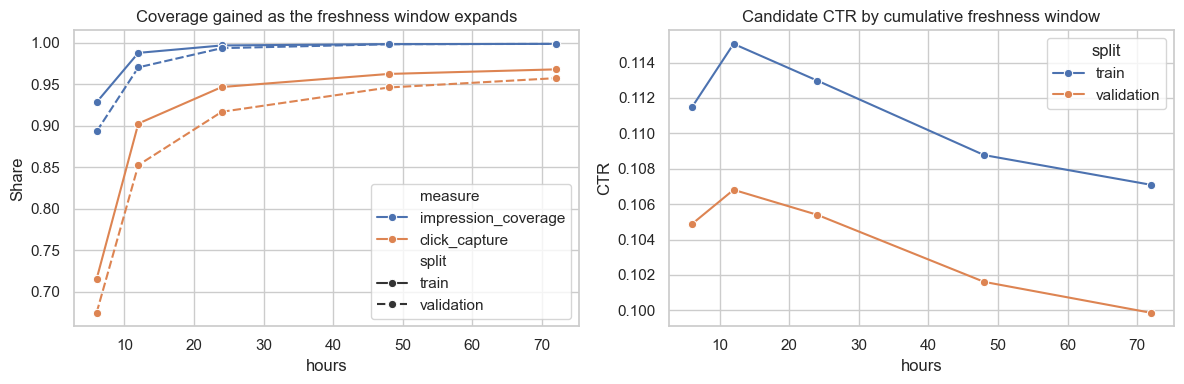

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
long_window = window_metrics.melt(
    id_vars=["split", "hours"],
    value_vars=["impression_coverage", "click_capture"],
    var_name="measure", value_name="share",
)
sns.lineplot(long_window, x="hours", y="share", hue="measure", style="split", marker="o", ax=axes[0])
axes[0].set(title="Coverage gained as the freshness window expands", ylabel="Share")
sns.lineplot(window_metrics, x="hours", y="candidate_ctr", hue="split", marker="o", ax=axes[1])
axes[1].set(title="Candidate CTR by cumulative freshness window", ylabel="CTR")
plt.tight_layout()
plt.show()

**Interpretation.** A 12-hour window covers 98.8% of train impressions and captures 90.3% of train clicks; validation reaches 97.0% coverage and 85.3% click capture. Expanding to 24 hours raises those figures to 99.6% and 94.7% in train, and 99.3% and 91.7% in validation. Later windows add less while candidate CTR declines. Use 24 hours as the working experiment window, but retain 12 hours as the main competing deployment definition.

## 4. Create a temporal development experiment

**Method.** Train on the earlier period and test on the later period, using a smaller set of complete impressions for repeated experiments.

Fit on the supplied training period and evaluate on the later validation period. Select complete impressions with a deterministic hash, then keep every eligible candidate from each selected slate. This preserves ranking groups. It also keeps repeated transformation and regularisation experiments practical. All earlier descriptive results remain full-data results.

In [ ]:
SAMPLE_MODULUS = 1000
dev = query(f"""
SELECT b.split, b.impression_id, u.position::INTEGER AS position,
       len(b.article_ids_inview)::INTEGER AS slate_size,
       list_contains(b.article_ids_clicked, u.article_id)::INTEGER AS clicked,
       date_diff('second', a.published_time, b.impression_time) / 3600.0 AS article_age_hours,
       length(coalesce(a.title, ''))::INTEGER AS title_length,
       length(coalesce(a.body, ''))::INTEGER AS body_length,
       coalesce(len(a.ner_clusters), 0)::INTEGER AS entity_count,
       coalesce(len(a.image_ids), 0)::INTEGER AS image_count,
       coalesce(len(a.topics), 0)::INTEGER AS topic_count,
       coalesce(a.premium, false)::INTEGER AS premium,
       coalesce(a.category_str, 'missing') AS category
FROM (
    SELECT * FROM behaviors
    WHERE hash(impression_id) % {SAMPLE_MODULUS} = 0
) b, UNNEST(b.article_ids_inview) WITH ORDINALITY AS u(article_id, position)
JOIN articles a ON a.article_id = u.article_id
WHERE date_diff('second', a.published_time, b.impression_time) BETWEEN 0 AND 86400
""")

In [ ]:
train_dev = dev.loc[dev["split"].eq("train")].copy()
valid_dev = dev.loc[dev["split"].eq("validation")].copy()
sample_size = dev.groupby("split").agg(
    candidates=("clicked", "size"),
    impressions=("impression_id", "nunique"),
    candidate_ctr=("clicked", "mean"),
).reset_index()
display(sample_size)

,split,candidates,impressions,candidate_ctr
0,train,101018,11989,0.1129
1,validation,109982,12515,0.1063


In [ ]:
full_24 = query("""
SELECT split, count(*) AS candidates,
       count(DISTINCT impression_id) AS impressions,
       avg(clicked) AS candidate_ctr,
       avg(article_age_hours) AS mean_age_hours,
       avg(position) AS mean_position,
       avg(slate_size) AS mean_slate_size
FROM candidate_features
WHERE article_age_hours BETWEEN 0 AND 24
GROUP BY split ORDER BY split
""").assign(source="full")
sample_24 = dev.groupby("split").agg(
    candidates=("clicked", "size"), impressions=("impression_id", "nunique"),
    candidate_ctr=("clicked", "mean"), mean_age_hours=("article_age_hours", "mean"),
    mean_position=("position", "mean"), mean_slate_size=("slate_size", "mean"),
).reset_index().assign(source="development sample")
representativeness = pd.concat([full_24, sample_24], ignore_index=True)
display(representativeness)

,split,candidates,impressions,candidate_ctr,mean_age_hours,mean_position,mean_slate_size,source
0,train,101654914,12021894,0.1130,4.1074,8.6045,16.2087,full
1,validation,110018928,12481992,0.1054,4.4795,9.8236,18.6466,full
2,train,101018,11989,0.1129,4.0962,8.6335,16.2476,development sample
3,validation,109982,12515,0.1063,4.4828,9.8355,18.6156,development sample


**Interpretation.** The deterministic sample retains 11,989 train impressions and 12,515 validation impressions with complete eligible slates. Its CTR, mean article age, position, and slate size closely match the full 24-hour population. Use it to screen alternatives quickly, while keeping full-data tables as the descriptive evidence.

## 5. Inspect every candidate attribute before transformation

**Method.** Plot every model variable before transforming it so skew, imbalance, and unusual values are easy to see.

Aggregate the full 24-hour training population into weighted distributions. This avoids loading 101.7 million candidate rows into pandas while still counting every row. The matrix contains all model attributes: one continuous variable, one ordinal variable, six counts, two binary variables, and one nominal category. Numeric panels show the central 99.5% so extreme tails do not flatten the main distribution; every frequency still contributes to the denominator.

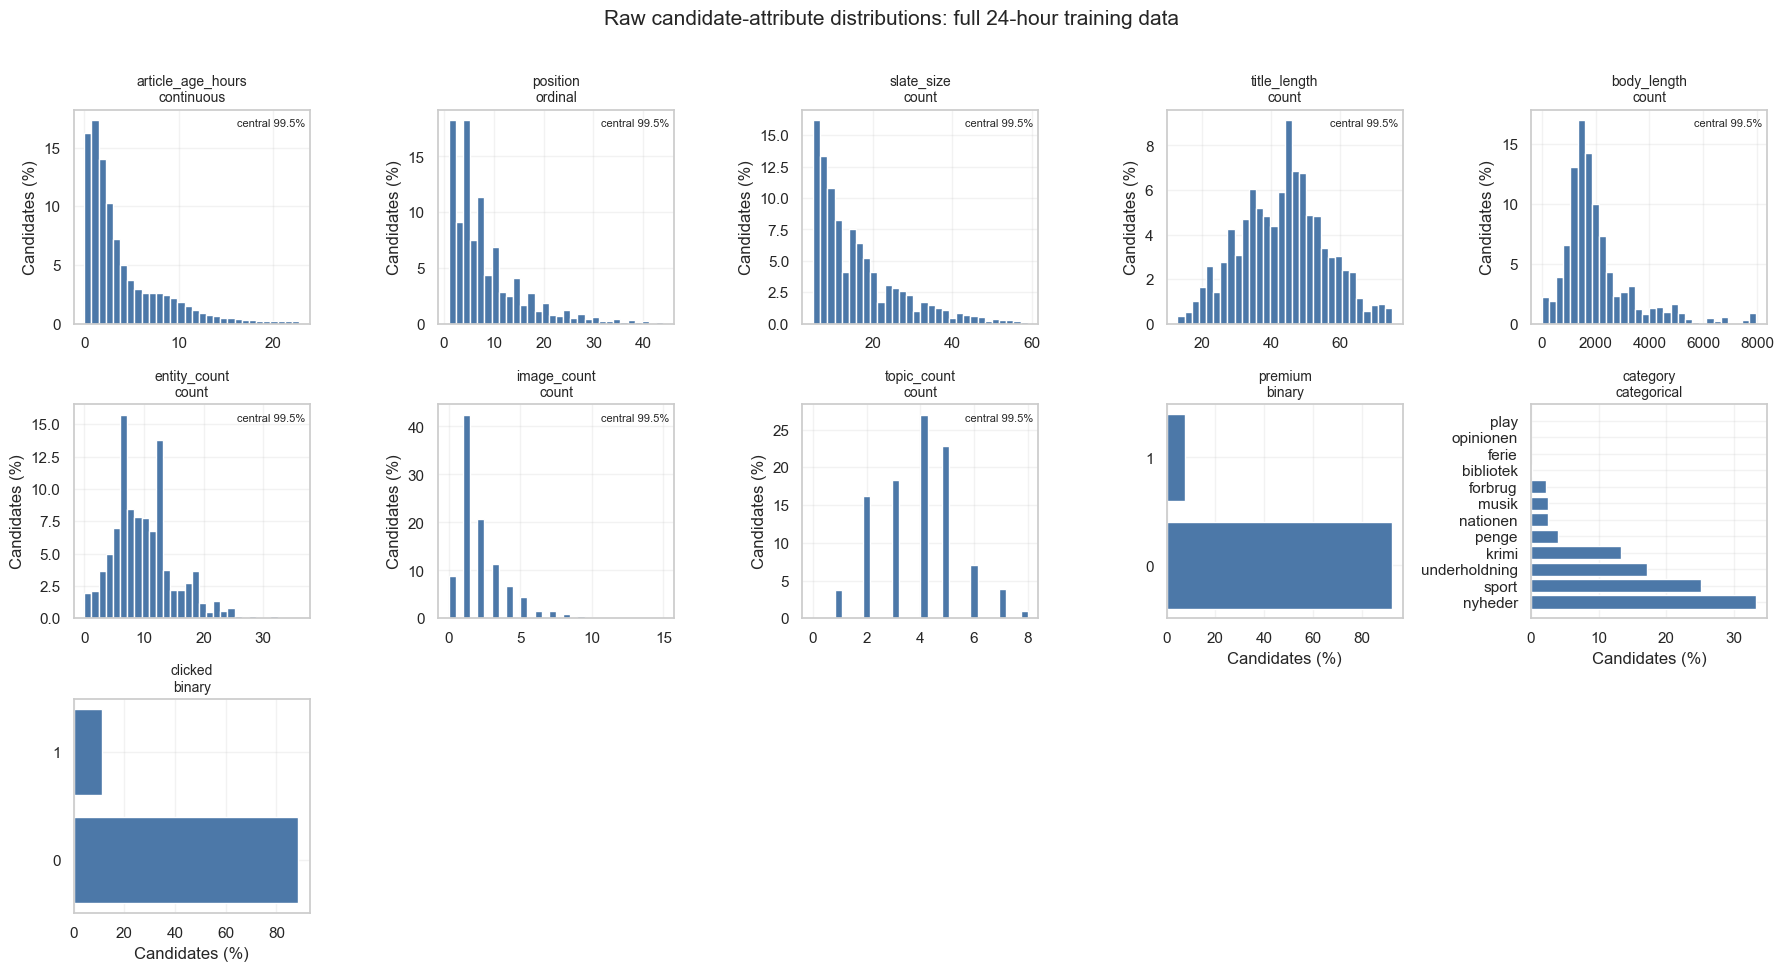

In [ ]:
distribution_sql = ",\n".join(
    f'histogram("{feature}") AS "{feature}"'
    for feature in COLD_START_FEATURE_TYPES
)
full_distribution_maps = query(f"""
SELECT {distribution_sql}
FROM candidate_features
WHERE split='train' AND article_age_hours BETWEEN 0 AND 24
""").iloc[0].to_dict()
raw_distribution = distribution_frame_from_maps(full_distribution_maps)
plot_distribution_matrix(
    raw_distribution, COLD_START_FEATURE_TYPES,
    title="Raw candidate-attribute distributions: full 24-hour training data",
)
plt.show()

In [ ]:
baseline_model, baseline_scores, baseline_metrics = fit_logistic_model(
    train_dev,
    valid_dev,
    numeric_transforms={"position": "raw", "slate_size": "raw"},
)
baseline_result = pd.DataFrame([{"model": "released-order diagnostic", **baseline_metrics}])
display(baseline_result)

,model,log_loss,pr_auc,roc_auc,ndcg_at_10,mrr
0,released-order diagnostic,0.3174,0.1899,0.6954,0.5131,0.3944


**Interpretation.** Released-list position and slate size reach 0.5131 NDCG@10 and 0.3174 log loss. Because EB-NeRD shuffles `article_ids_inview`, this `position` is not the original display position and cannot measure presentation bias. Keep this result only as an ordering-artifact diagnostic; deployable article-side features must improve temporal validation beyond it.

**Interpretation.** Recency, released-list position, slate size, body length, entity count, and image count have visible right tails. Title length and topic count are comparatively compact. Premium articles and clicks are minority classes, while four categories dominate candidate exposure. Use logarithmic views to inspect skew, then let temporal validation decide what the model keeps.

## 6. Test transformations instead of assuming linear effects

**Method.** Transform each numerical variable in several ways, fit the same logistic regression each time, and keep methods that improve later-period results without harming ranking.

In [ ]:
feature_methods = {
    "article_age_hours": ("raw", "log1p", "binned", "spline"),
    "position": ("raw", "log1p", "binned", "spline"),
    "slate_size": ("raw", "log1p", "binned", "spline"),
    "title_length": ("raw", "log1p", "yeo-johnson", "binned", "spline"),
    "body_length": ("raw", "log1p", "yeo-johnson", "binned", "spline"),
    "entity_count": ("raw", "log1p", "sqrt", "binned"),
    "image_count": ("raw", "log1p", "sqrt", "binned"),
    "topic_count": ("raw", "log1p", "sqrt", "binned"),
}
screens = []
for feature, methods in feature_methods.items():
    controls = tuple(name for name in ("article_age_hours", "position", "slate_size") if name != feature)
    screens.append(screen_numeric_transforms(
        train_dev, valid_dev, feature=feature, controls=controls, methods=methods,
    ))
transform_results = pd.concat(screens, ignore_index=True)

,feature,transform,loss_change,ndcg_change,ndcg_at_10
0,article_age_hours,log1p,-0.0023,0.0000,0.5979
1,body_length,raw,0.0000,0.0000,0.5713
2,entity_count,raw,0.0000,0.0000,0.5737
3,image_count,raw,0.0000,0.0000,0.5822
4,position,raw,0.0000,0.0000,0.5979
5,slate_size,spline,-0.0019,0.0002,0.5980
6,title_length,raw,0.0000,0.0000,0.5639
7,topic_count,binned,-0.0001,0.0021,0.5870


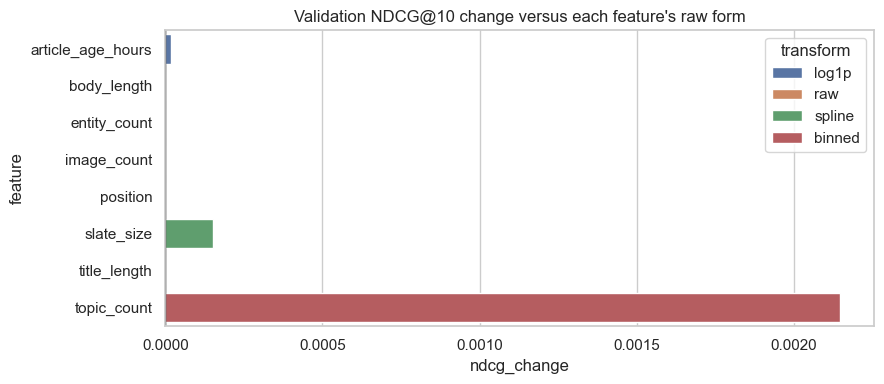

In [ ]:
raw_results = transform_results.loc[transform_results["transform"].eq("raw"), [
    "feature", "log_loss", "ndcg_at_10"
]].rename(columns={"log_loss": "raw_log_loss", "ndcg_at_10": "raw_ndcg"})
transform_candidates = transform_results.merge(raw_results, on="feature")
ranking_ok = transform_candidates["ndcg_at_10"] >= transform_candidates["raw_ndcg"] - 0.001
best_transforms = (
    transform_candidates.loc[ranking_ok]
    .sort_values(["feature", "log_loss", "ndcg_at_10"], ascending=[True, True, False])
    .groupby("feature", as_index=False).first()
)
best_transforms["loss_change"] = best_transforms["log_loss"] - best_transforms["raw_log_loss"]
best_transforms["ndcg_change"] = best_transforms["ndcg_at_10"] - best_transforms["raw_ndcg"]
display(best_transforms[["feature", "transform", "loss_change", "ndcg_change", "ndcg_at_10"]])

plt.figure(figsize=(9, 4))
sns.barplot(best_transforms, x="ndcg_change", y="feature", hue="transform", dodge=False)
plt.axvline(0, color="black", linewidth=1)
plt.title("Validation NDCG@10 change versus each feature's raw form")
plt.tight_layout()
plt.show()

**Interpretation.** Select transformations by temporal validation, not by whether a histogram looks normal. `log1p` age reduces log loss by 0.0023 without reducing NDCG@10, while a spline helps slate size slightly. Keep position, title length, body length, entity count, and image count raw because alternatives do not improve ranking safely. Binning topic count adds a small NDCG gain.

## 7. Compare the same attributes after simple display transformations

**Method.** Plot the same variables again after simple transformations so the change in each distribution is easy to see.

Apply `log1p` only to the visibly right-skewed non-negative attributes. Keep the same feature order, chart function, five-column layout, and full-data frequencies so each panel can be compared directly with the raw matrix. These visual transforms are diagnostic; the validation screen above remains the model-selection evidence.

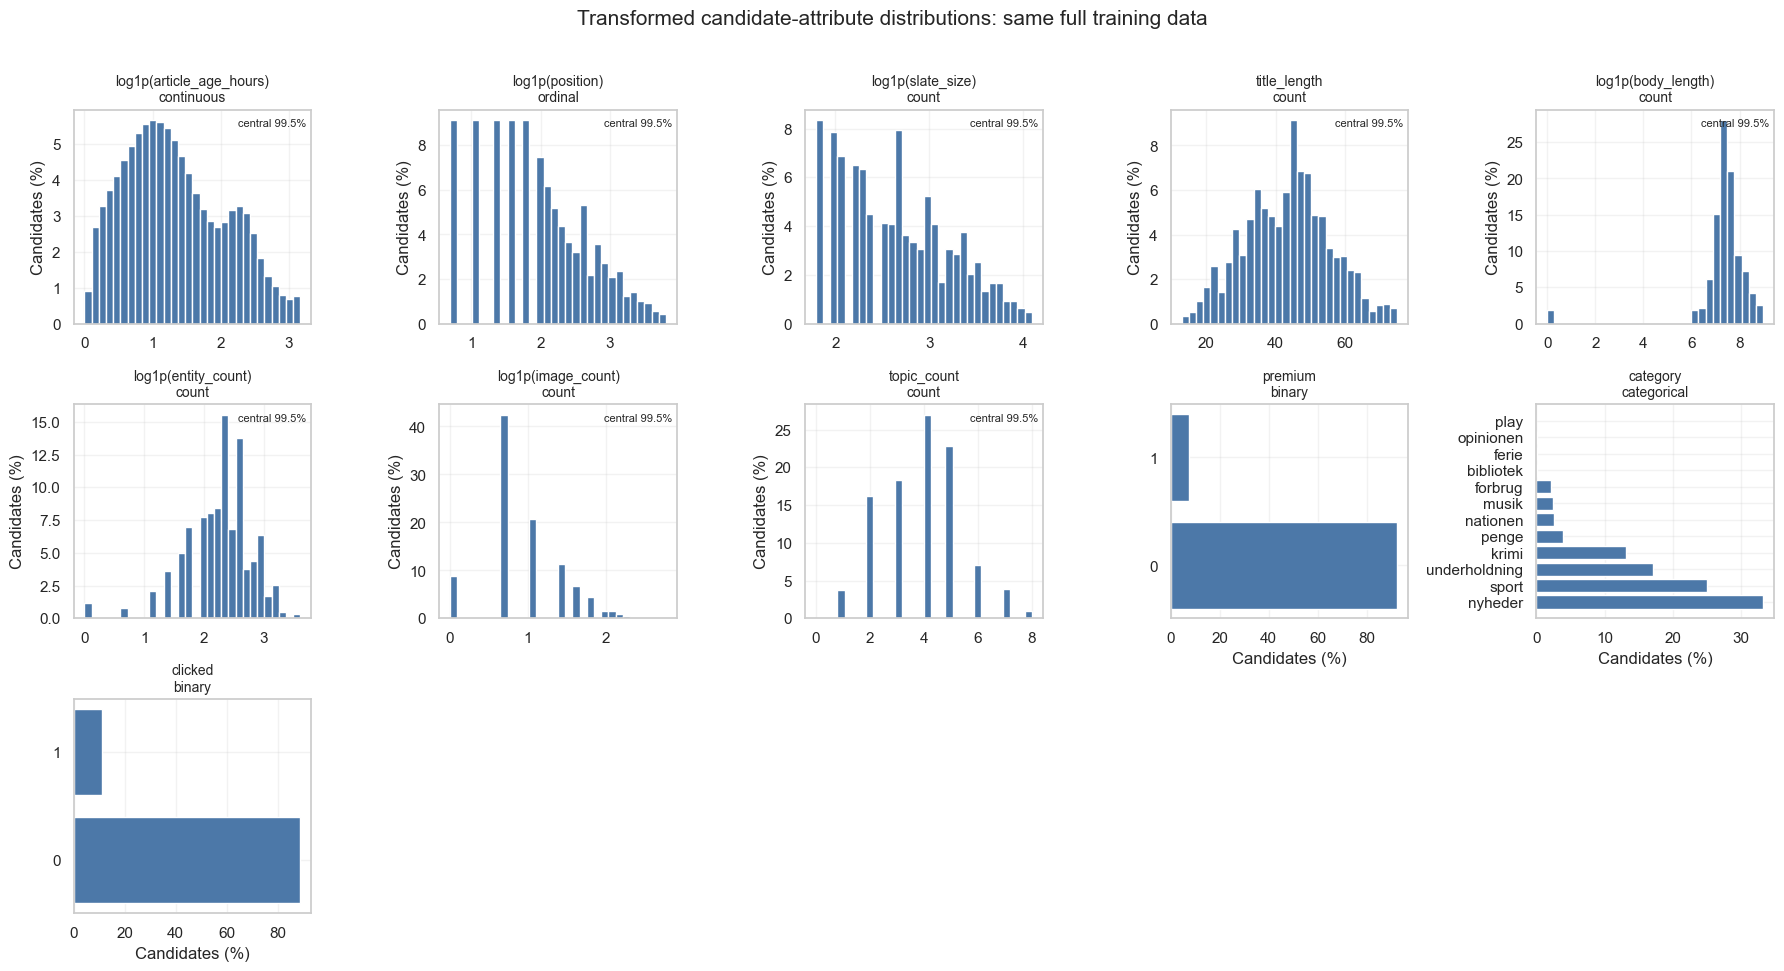

In [ ]:
transformed_distribution = transform_distribution_frame(
    raw_distribution, COLD_START_DISPLAY_TRANSFORMS,
)
plot_distribution_matrix(
    transformed_distribution, COLD_START_FEATURE_TYPES,
    title="Transformed candidate-attribute distributions: same full training data",
)
plt.show()

**Interpretation.** The log views spread dense low values and compress long tails without changing candidate frequencies. They make age, slate size, body length, entity count, and image count easier to inspect. The categorical and binary panels remain unchanged. This visual improvement does not imply that every log transform improves ranking.

## 8. Check multicollinearity after practical transformations

**Method.** Use correlations and VIF scores to check whether numerical variables repeat too much of the same information.

In [ ]:
vif_frame = pd.DataFrame({
    "log_age": np.log1p(train_dev["article_age_hours"]),
    "log_position": np.log1p(train_dev["position"]),
    "log_slate_size": np.log1p(train_dev["slate_size"]),
    "title_length": train_dev["title_length"],
    "log_body_length": np.log1p(train_dev["body_length"]),
    "log_entity_count": np.log1p(train_dev["entity_count"]),
    "log_image_count": np.log1p(train_dev["image_count"]),
    "log_topic_count": np.log1p(train_dev["topic_count"]),
    "premium": train_dev["premium"],
})
vif_result = numeric_vif(vif_frame)
spearman = vif_frame.corr(method="spearman")
display(vif_result)

,feature,vif
0,log_slate_size,1.7500
1,log_position,1.6702
2,log_body_length,1.3755
3,log_entity_count,1.3584
4,premium,1.3338
5,log_image_count,1.2559
6,log_age,1.1603
7,log_topic_count,1.0516
8,title_length,1.0260


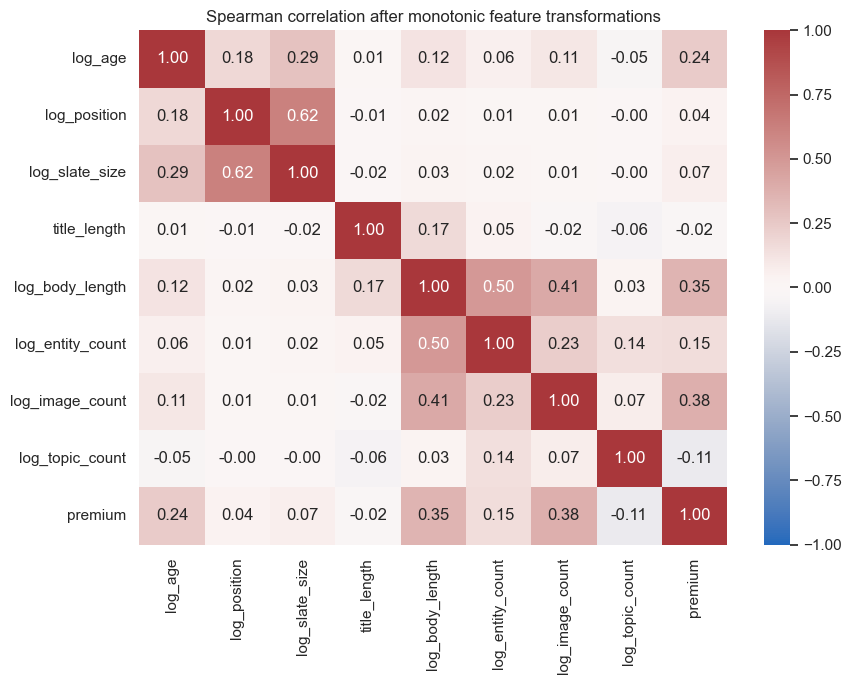

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(spearman, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f")
plt.title("Spearman correlation after monotonic feature transformations")
plt.tight_layout()
plt.show()

**Interpretation.** The maximum VIF is 1.75, so the compact numeric set shows no serious multicollinearity. Do not remove variables mechanically. Use ablation to test incremental value and let regularisation handle the mild remaining dependence.

## 9. Add feature groups and check what survives

**Method.** Add recency, content, metadata, and interaction features one group at a time to see what each group contributes.

In [ ]:
for frame in (train_dev, valid_dev):
    frame["has_entities"] = frame["entity_count"].gt(0).astype(int)
    frame["has_images"] = frame["image_count"].gt(0).astype(int)
    frame["has_topics"] = frame["topic_count"].gt(0).astype(int)
    frame["age_x_position"] = np.log1p(frame["article_age_hours"]) * np.log1p(frame["position"])
    frame["age_x_premium"] = np.log1p(frame["article_age_hours"]) * frame["premium"]

selected = dict(zip(best_transforms["feature"], best_transforms["transform"]))
order_context = {name: selected[name] for name in ("position", "slate_size")}
recency = {**order_context, "article_age_hours": selected["article_age_hours"]}
content = {**recency, **{name: selected[name] for name in (
    "title_length", "body_length", "entity_count", "image_count", "topic_count",
)}, "has_entities": "raw", "has_images": "raw", "has_topics": "raw"}
metadata = {**content, "premium": "raw"}
interactions = {**metadata, "age_x_position": "raw", "age_x_premium": "raw"}
ablation_specs = [
    ("released order + slate", order_context, ()), ("+ recency", recency, ()),
    ("+ content", content, ()), ("+ metadata", metadata, ("category",)),
    ("+ interactions", interactions, ("category",)),
]

,model,log_loss,pr_auc,roc_auc,ndcg_at_10,mrr
0,released order + slate,0.3158,0.1922,0.6951,0.5161,0.3983
1,+ recency,0.3112,0.2017,0.7142,0.5973,0.4761
2,+ content,0.3104,0.2038,0.7170,0.5884,0.4690
3,+ metadata,0.3104,0.2046,0.7176,0.5905,0.4741
4,+ interactions,0.3100,0.2032,0.7186,0.5893,0.4714


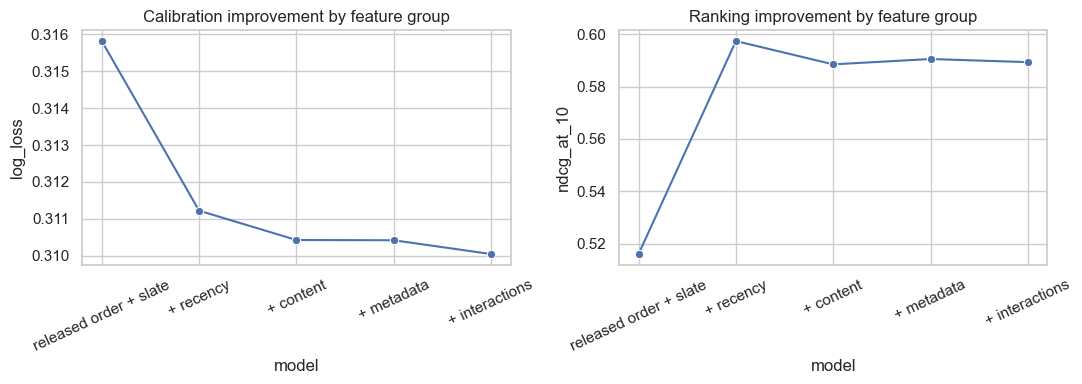

In [ ]:
ablation_rows = []
for name, numeric, categorical in ablation_specs:
    _, _, metrics = fit_logistic_model(
        train_dev, valid_dev,
        numeric_transforms=numeric,
        categorical=categorical,
    )
    ablation_rows.append({"model": name, **metrics})
ablation = pd.DataFrame(ablation_rows)
display(ablation)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.lineplot(ablation, x="model", y="log_loss", marker="o", ax=axes[0])
sns.lineplot(ablation, x="model", y="ndcg_at_10", marker="o", ax=axes[1])
axes[0].tick_params(axis="x", rotation=25)
axes[1].tick_params(axis="x", rotation=25)
axes[0].set_title("Calibration improvement by feature group")
axes[1].set_title("Ranking improvement by feature group")
plt.tight_layout()
plt.show()

**Interpretation.** Recency provides the main article-side improvement: NDCG@10 rises from 0.5161 to 0.5973 and log loss falls from 0.3158 to 0.3112. Content lowers log loss further to 0.3104 but reduces NDCG@10 to 0.5884. Metadata and interactions do not recover the recency-only ranking result. Adding columns is not progress when ranking quality declines.

## 10. Tune regularisation and diagnose the selected model

**Method.** Try several logistic-regression penalties and strengths, then compare ranking, probability accuracy, and calibration on the later period.

In [ ]:
grid = [
    ("l2", c, None, None) for c in (0.02, 0.05, 0.2, 1.0, 5.0)
] + [
    ("l1", c, None, None) for c in (0.02, 0.05, 0.2, 1.0)
] + [
    ("elasticnet", c, 0.5, None) for c in (0.05, 0.2, 1.0)
] + [("l2", 0.05, None, "balanced")]
grid_rows, grid_scores = [], {}
for penalty, c_value, l1_ratio, class_weight in grid:
    key = f"{penalty}|{c_value}|{l1_ratio}|{class_weight}"
    _, scores, metrics = fit_logistic_model(
        train_dev, valid_dev, numeric_transforms=metadata,
        categorical=("category",), penalty=penalty, c=c_value,
        l1_ratio=l1_ratio, class_weight=class_weight,
        max_iter=1500, tol=1e-3,
    )
    grid_scores[key] = scores
    grid_rows.append({"key": key, "penalty": penalty, "C": c_value,
                      "l1_ratio": l1_ratio, "class_weight": class_weight, **metrics})
grid_results = pd.DataFrame(grid_rows)
grid_results["selection_rank"] = grid_results["log_loss"].rank() + grid_results["ndcg_at_10"].rank(ascending=False)
display(grid_results.sort_values(["selection_rank", "log_loss"]).head(10))

,key,penalty,C,l1_ratio,class_weight,log_loss,pr_auc,roc_auc,ndcg_at_10,mrr,selection_rank
5,l1|0.02|None|None,l1,0.0200,NaN,None,0.3105,0.2039,0.7175,0.5921,0.4749,7.0000
9,elasticnet|0.05|0.5|None,elasticnet,0.0500,0.5000,None,0.3104,0.2044,0.7176,0.5909,0.4741,8.0000
0,l2|0.02|None|None,l2,0.0200,NaN,None,0.3106,0.2032,0.7165,0.5915,0.4751,11.0000
10,elasticnet|0.2|0.5|None,elasticnet,0.2000,0.5000,None,0.3104,0.2045,0.7175,0.5903,0.4737,12.0000
1,l2|0.05|None|None,l2,0.0500,NaN,None,0.3107,0.2031,0.7164,0.5911,0.4746,13.0000
6,l1|0.05|None|None,l1,0.0500,NaN,None,0.3104,0.2042,0.7175,0.5896,0.4723,14.0000
11,elasticnet|1.0|0.5|None,elasticnet,1.0000,0.5000,None,0.3104,0.2045,0.7175,0.5902,0.4737,14.0000
12,l2|0.05|None|balanced,l2,0.0500,NaN,balanced,0.6078,0.2031,0.7187,0.5939,0.4774,14.0000
2,l2|0.2|None|None,l2,0.2000,NaN,None,0.3107,0.2031,0.7163,0.5911,0.4748,15.0000
7,l1|0.2|None|None,l1,0.2000,NaN,None,0.3105,0.2044,0.7174,0.5900,0.4734,17.0000


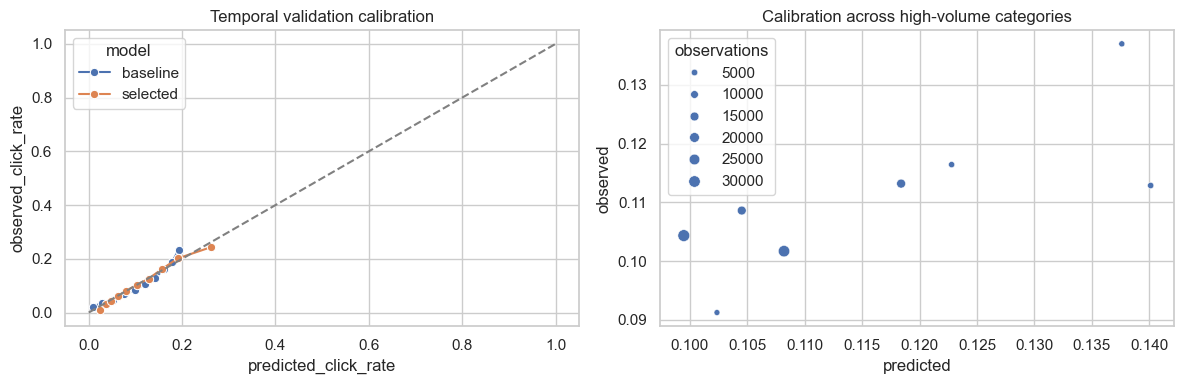

In [ ]:
best_grid = grid_results.sort_values(["selection_rank", "log_loss"]).iloc[0]
best_scores = grid_scores[best_grid["key"]]
baseline_calibration = calibration_table(valid_dev["clicked"], baseline_scores).assign(model="baseline")
best_calibration = calibration_table(valid_dev["clicked"], best_scores).assign(model="selected")
calibration = pd.concat([baseline_calibration, best_calibration], ignore_index=True)

category_diagnostic = valid_dev[["category", "clicked"]].copy()
category_diagnostic["predicted"] = best_scores
category_diagnostic = category_diagnostic.groupby("category").agg(
    observations=("clicked", "size"), observed=("clicked", "mean"), predicted=("predicted", "mean"),
).nlargest(8, "observations").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(calibration, x="predicted_click_rate", y="observed_click_rate", hue="model", marker="o", ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey")
sns.scatterplot(category_diagnostic, x="predicted", y="observed", size="observations", ax=axes[1])
axes[0].set_title("Temporal validation calibration")
axes[1].set_title("Calibration across high-volume categories")
plt.tight_layout()
plt.show()

## 11. Main findings and next decisions

**Method.** Summarise what the experiments show, what remains uncertain, and what the group still needs to decide.

- Compare 12 and 24 hours as the main cold-start definitions. The full-data curve does not justify extending the definition automatically to 48 or 72 hours.
- Do not interpret released-list `position` as page placement. EB-NeRD shuffles the in-view order, so the 0.5131 NDCG@10 result is only an ordering-artifact diagnostic.
- Model recency with `log1p` or another guarded nonlinear form. Adding recency raises NDCG@10 to 0.5973, the largest experiment gain.
- Keep content and metadata only if later full-scale tests confirm them. They improve log loss but reduce ranking quality in this development experiment.
- Do not remove features for multicollinearity now. The maximum VIF is only 1.75.
- Regularisation does not rescue the richer model: the selected L1 result reaches 0.5921 NDCG@10, below the recency-only model. Class weighting severely worsens probability calibration.
- Do not use final modification fields or lifetime popularity totals until point-in-time values can be reconstructed.
- Do not treat missing demo vectors as zero embeddings. Obtain or generate full-catalogue, point-in-time vectors before testing embedding similarity.
- Treat this model search as feature-screening evidence. Refit the shortlisted specification on the full training period and confirm it on the untouched temporal test period before reporting final performance.

The group still needs to decide the business objective, final cold-start window, whether to exclude released-list position, embedding source, and final ranking metric.

## 12. Release resources

**Method.** Close DuckDB and delete its temporary files so every new run starts cleanly.

In [ ]:
con.close()
shutil.rmtree(DUCKDB_TMP, ignore_errors=True)